**Classification Assignment**

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Loading The Dataset

In [2]:
df = pd.read_csv("diabetes_prediction_dataset.csv")

In [3]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [4]:
df.shape

(100000, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Data Cleaning and Preprocessing

In [6]:
df.duplicated().sum()

np.int64(3854)

In [8]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [9]:
df = df.drop_duplicates()
df.shape

(96146, 9)

In [10]:
df.duplicated().sum()

np.int64(0)

Outlier Detection

<Axes: ylabel='bmi'>

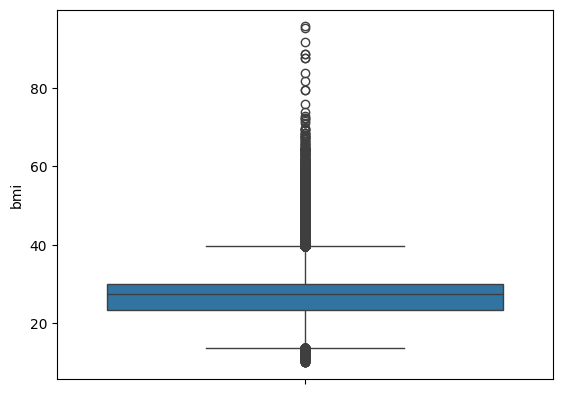

In [11]:
sns.boxplot(df["bmi"])

In [12]:
q1=df["bmi"].quantile(0.25)
q3=df["bmi"].quantile(0.75)
iqr=q3-q1
upper_bound=q3+1.5*iqr
lower_bound=q1-1.5*iqr
df["bmi"]=df["bmi"].clip(upper=upper_bound,lower=lower_bound)

<Axes: ylabel='bmi'>

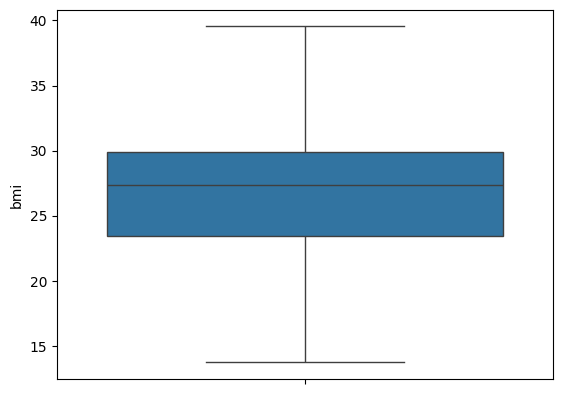

In [13]:
sns.boxplot(df["bmi"])

Encoding

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 96146 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               96146 non-null  object 
 1   age                  96146 non-null  float64
 2   hypertension         96146 non-null  int64  
 3   heart_disease        96146 non-null  int64  
 4   smoking_history      96146 non-null  object 
 5   bmi                  96146 non-null  float64
 6   HbA1c_level          96146 non-null  float64
 7   blood_glucose_level  96146 non-null  int64  
 8   diabetes             96146 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 7.3+ MB


In [15]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['gender']=le.fit_transform(df['gender'])
df['smoking_history']=le.fit_transform(df['smoking_history'])

In [16]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,4,25.19,6.6,140,0
1,0,54.0,0,0,0,27.32,6.6,80,0
2,1,28.0,0,0,4,27.32,5.7,158,0
3,0,36.0,0,0,1,23.45,5.0,155,0
4,1,76.0,1,1,1,20.14,4.8,155,0


Scaling

In [17]:
x = df.drop("diabetes", axis=1)
y = df["diabetes"]

Split the dataset

In [18]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

Applying StandardScaler

In [21]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()
cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
x_train_scaled[cols] = sc.fit_transform(x_train[cols])
x_test_scaled[cols] = sc.transform(x_test[cols])

In [23]:
x_train_scaled.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
46612,0,-0.301980,0,0,0,0.762226,0.994649,0.412328
31612,0,-1.842405,0,0,0,-1.996565,-1.428149,-0.198580
96143,0,0.811043,0,0,2,-1.032508,0.901465,-0.931669
95691,1,1.078169,0,0,4,0.005838,0.435542,-0.198580
37658,1,0.276792,0,0,5,-0.500672,-0.682673,0.167965


**Building Models**

Logistic Regression

In [26]:
from sklearn.linear_model import LogisticRegression
lg=LogisticRegression()
lg.fit(x_train_scaled,y_train)
lg_pred=lg.predict(x_test_scaled)

In [27]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
print(accuracy_score(y_test,lg_pred))
print(precision_score(y_test,lg_pred))
print(recall_score(y_test,lg_pred))
print(f1_score(y_test,lg_pred))
print(confusion_matrix(y_test,lg_pred))

0.9568382735309412
0.8566853482786229
0.6217315514235909
0.7205387205387206
[[17330   179]
 [  651  1070]]


K Nearest Neighbors(KNN)

In [28]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled,y_train)
knn_pred=knn.predict(x_test_scaled)

In [29]:
print(accuracy_score(y_test,knn_pred))
print(precision_score(y_test,knn_pred))
print(recall_score(y_test,knn_pred))
print(f1_score(y_test,knn_pred))
print(confusion_matrix(y_test,knn_pred))

0.9591783671346854
0.89
0.620569436374201
0.7312564190345772
[[17377   132]
 [  653  1068]]


Naive Bayes

In [30]:
from sklearn.naive_bayes import GaussianNB
nb=GaussianNB()
nb.fit(x_train_scaled,y_train)
nb_pred=nb.predict(x_test_scaled)

In [31]:
print(accuracy_score(y_test,nb_pred))
print(precision_score(y_test,nb_pred))
print(recall_score(y_test,nb_pred))
print(f1_score(y_test,nb_pred))
print(confusion_matrix(y_test,nb_pred))

0.8981279251170047
0.45054031587697424
0.6298663567693201
0.5253210564574752
[[16187  1322]
 [  637  1084]]


Decision Tree

In [32]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier()
dt.fit(x_train_scaled,y_train)
dt_pred=dt.predict(x_test_scaled)

In [33]:
print(accuracy_score(y_test,dt_pred))
print(precision_score(y_test,dt_pred))
print(recall_score(y_test,dt_pred))
print(f1_score(y_test,dt_pred))
print(confusion_matrix(y_test,dt_pred))

0.947581903276131
0.6972883231876038
0.7321324811156305
0.7142857142857143
[[16962   547]
 [  461  1260]]


Support Vector Machine (SVM)

In [34]:
from sklearn.svm import SVC
sv=SVC()
sv.fit(x_train_scaled,y_train)
sv_pred=sv.predict(x_test_scaled)

In [35]:
print(accuracy_score(y_test,sv_pred))
print(precision_score(y_test,sv_pred))
print(recall_score(y_test,sv_pred))
print(f1_score(y_test,sv_pred))
print(confusion_matrix(y_test,sv_pred))

0.9609464378575143
0.9889112903225806
0.5700174317257408
0.7231846664209363
[[17498    11]
 [  740   981]]


Random Forest

In [36]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier()
rf.fit(x_train_scaled,y_train)
rf_pred=rf.predict(x_test_scaled)

In [37]:
print(accuracy_score(y_test,rf_pred))
print(precision_score(y_test,rf_pred))
print(recall_score(y_test,rf_pred))
print(f1_score(y_test,rf_pred))
print(confusion_matrix(y_test,rf_pred))

0.9674986999479979
0.9335443037974683
0.6856478791400349
0.7906197654941374
[[17425    84]
 [  541  1180]]


Comparison for all 6 Models

In [38]:

models = {
    "Logistic Regression": lg_pred,
    "KNN": knn_pred,
    "Naive Bayes": nb_pred,
    "Decision Tree": dt_pred,
    "SVM": sv_pred,
    "Random Forest": rf_pred
}

results = []

for name, pred in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred)
    })

comparison = pd.DataFrame(results)
comparison = comparison.sort_values(
    by="F1-score", ascending=False
)

comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score
5,Random Forest,0.9675,0.9335,0.6856,0.7906
1,KNN,0.9592,0.8900,0.6206,0.7313
4,SVM,0.9609,0.9889,0.5700,0.7232
0,Logistic Regression,0.9568,0.8567,0.6217,0.7205
3,Decision Tree,0.9476,0.6973,0.7321,0.7143
2,Naive Bayes,0.8981,0.4505,0.6299,0.5253


Plot the best model's confusion matrix

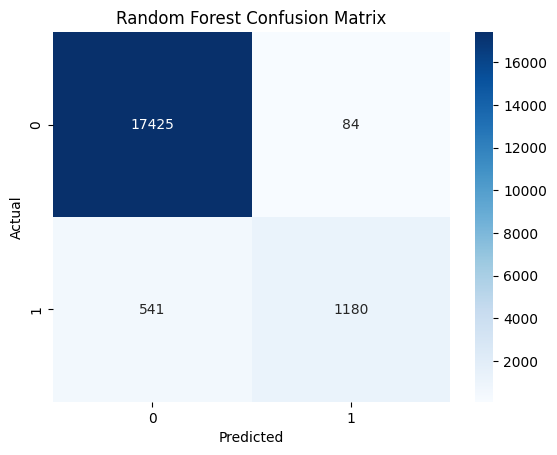

In [42]:
sns.heatmap(
    confusion_matrix(y_test, rf_pred),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

**Model Selection Justification**

I trained and evaluated six classification algorithms: Logistic Regression, KNN, Naive Bayes, Decision Tree, SVM, and Random Forest. Random Forest achieved the highest accuracy of **96.75%** and F1-score of **79.06%**, with precision of 93.35% and recall of 68.56%, making it the best overall model based on accuracy and F1-score. Although Decision Tree achieved higher recall, Random Forest provided a stronger overall balance between precision and recall for this assignment.